# Las pruebas de validación de IRRBB: choques de referencia, suma de partes, estabilidad de parámetros y el cambio ante un incumplimiento de límite

**Pregunta:** ¿cuáles de las siete pruebas de validación de IRRBB del motor marcan las debilidades del banco que quebró en 2023 en sus tres fechas de valoración, y cada prueba pasa de verde a rojo cuando se rompe a propósito su insumo, de modo que un verde signifique algo?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los notebooks 01 a 04 de este tema
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este notebook puedes:

- nombrar las siete pruebas de validación de IRRBB del motor, qué prueba cada una y la regla que da su luz;
- correr cada prueba con los insumos que traen los documentos versionados y leer su estadístico y su luz en las tres fechas;
- mostrar que una prueba no es vacía cambiando un insumo y mirando cambiar su luz;
- leer la estabilidad de los pesos de la cartera replicante entre ventanas de estimación y explicar por qué es el resultado más débil del caso;
- decir qué afirman las pruebas y qué no: son umbrales internos de Contraste, no umbrales regulatorios.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.irrbb import eve_nii, slotting
from riskvalidation.validation import irrbb as rv_irrbb

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

Los datos son el caso C14 (el riesgo de tasa de interés en el libro de banca del banco que quebró en marzo de 2023) en tres fechas de valoración, 2021-Q4, 2022-Q2 y 2022-Q4, y el caso C15 (el Banco Andino sintético sobre un balance en pesos y UF) para la prueba chilena. C14 usa los reportes de condición de la FDIC (FDIC BankFind financials, https://api.fdic.gov/banks/financials) y la curva a la par del Tesoro de EE. UU. (https://home.treasury.gov/resource-center/data-chart-center/interest-rates); C15 usa los agregados de la CMF de agosto de 2026 y las curvas del Banco Central de Chile (serie F022); las cuatro son fuentes públicas de la clase de licencia `mirror-allowed`. C14 es real en agregado y sintético en comportamiento; C15 es un banco sintético sobre curvas reales.

- **Archivos que se leen:** `data/derived/C14/vd-2021-q4.json`, `vd-2022-q2.json` y `vd-2022-q4.json` (`outputs.balance_sheet`, `curve`, `scenarios`, `out_of_sample`) y `models-svb-2021-2022.json` (`fit.nmd_models`, los pesos replicantes por ventana), y `data/derived/C15/short-uf.json` (`outputs.legs`, `curves`, `eve`).

La celda siguiente carga los archivos.

In [2]:
# Cargar las tres fechas de valoración de C14, el documento de modelos y la variante C15 (tres carpetas bajo la raíz)
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived"
quarters = ("2021-Q4", "2022-Q2", "2022-Q4")
docs = {q: json.loads((derived / "C14" / f"vd-{q.lower()}.json").read_text(encoding="utf-8")) for q in quarters}
fit = json.loads((derived / "C14" / "models-svb-2021-2022.json").read_text(encoding="utf-8"))["fit"]
c15 = json.loads((derived / "C15" / "short-uf.json").read_text(encoding="utf-8"))
MID = slotting.bucket_grid().midpoints
LANG = "es"  # los campos bilingües de los documentos se leen en este idioma
LIGHT = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluado"}
battery = {}
print("fechas de valoración de C14:", [d["outputs"]["valuation_date"] for d in docs.values()])
print("C15:", c15["outputs"]["as_of"])

fechas de valoración de C14: ['2021-12-31', '2022-06-30', '2022-12-31']
C15: 2026-09-03


## Método

El motor guarda siete pruebas de validación de IRRBB en `riskvalidation.validation.irrbb`. Cada una es una función simple que devuelve un `TestResult` y declara su regla de luz en su docstring. Siguen las lecciones que la investigación convirtió en pruebas (dossier 05, D.7): una implementación debe reproducir los ejemplos del propio estándar, sus partes deben sumar el todo, un parámetro de comportamiento debe ser estable, la capa de comportamiento debe informarse junto a la lectura contractual, un cambio en un supuesto de comportamiento no debe coincidir con un exceso, y una proyección debe compararse con lo que ocurrió.

| Prueba | Qué prueba | Regla de la luz |
|---|---|---|
| `irrbb.srp31_92_goldens` | el ejemplo resuelto del estándar | verde si cada valor está dentro de su tolerancia |
| `irrbb.cmf_annex1_goldens` | las fórmulas y la tabla del Anexo 1 chileno | verde si los 19 casos son exactos |
| `irrbb.eve_sum_of_parts` | el EVE del todo es la suma de sus partidas | verde si el residuo relativo es como máximo `rel_tol` |
| `irrbb.nmd_parameter_stability` | pesos replicantes entre ventanas | verde, ámbar, rojo por la distancia de norma infinito |
| `irrbb.eve_with_without_behavioural` | las dos lecturas juntas | verde, ámbar, rojo; rojo si se esconde un exceso |
| `irrbb.behavioural_change_at_breach` | un cambio que coincide con un exceso | rojo si hay alguno |
| `irrbb.nii_out_of_sample` | proyección contra el cambio realizado | verde, ámbar, rojo por el error relativo |

Los umbrales son **umbrales internos de Contraste**, declarados así en cada docstring y registrados en el `policy_version` y en `extras["thresholds"]` del resultado; ninguno afirma cumplimiento. Una prueba que no se puede evaluar devuelve la luz `not_evaluated` con la razón en `notes`, nunca un número inventado.

### Paso 1: las dos pruebas de valores de referencia

Una prueba de valores de referencia recalcula un valor que la fuente primaria imprime y lo compara con la impresión. `irrbb.srp31_92_goldens` se leyó en el notebook 02 (los cuatro valores del ejemplo resuelto a 3,5 años). `irrbb.cmf_annex1_goldens` verifica 19 casos del Anexo 1 chileno: la tabla de compensación `cmf_pair` con ambos signos (8 casos), la tabla de tamaños de choque (5 filas), el cargo por reajustabilidad, el ejemplo de `annex1_delta_eve` (3 casos) y el ejemplo resuelto del Anexo 1 (2 casos). Su estadístico es el número de casos fallidos, y una excepción cuenta como caso fallido. La celda siguiente corre ambas y luego estrecha la tolerancia de la primera para mostrar cómo cambia su luz.

In [3]:
# Correr las dos pruebas de valores de referencia y luego estrechar la tolerancia de la primera
runs = [rv_irrbb.srp31_92_goldens(), rv_irrbb.cmf_annex1_goldens()]
tight = rv_irrbb.srp31_92_goldens(tolerance_bp=0.01)
for run in runs + [tight]:
    print(f"{run.test_id}: {LIGHT[run.light.value]} | estadístico {run.statistic:.4f} | n = {run.n}")
print("casos fallidos de la prueba chilena:", runs[1].extras.get("failed"))
print("tolerancias de la corrida estrecha:", tight.extras["thresholds"])
battery["irrbb.srp31_92_goldens"] = [runs[0].light.value] * 3
battery["irrbb.cmf_annex1_goldens"] = [runs[1].light.value] * 3

irrbb.srp31_92_goldens: verde | estadístico 0.0393 | n = 4
irrbb.cmf_annex1_goldens: verde | estadístico 0.0000 | n = 19
irrbb.srp31_92_goldens: rojo | estadístico 0.0393 | n = 4
casos fallidos de la prueba chilena: []
tolerancias de la corrida estrecha: {'tolerance_scalar': 0.0005, 'tolerance_bp': 0.01}


Las dos pruebas de valores de referencia corren solo sobre el motor: el estadístico de la primera es 0,0393 sobre cuatro valores, la desviación del aplanamiento respecto del -1,6 impreso, y la segunda pasa 19 de 19 casos del Anexo 1 chileno con una lista vacía de fallas. La tercera línea es el control: la misma prueba con una tolerancia de 0,01 pb en vez de 0,05 convierte el mismo estadístico en una falla, porque el valor impreso tiene un decimal y el motor no. De ahí se sigue que una prueba de valores de referencia es una afirmación sobre la precisión de la fuente y no sobre la corrección en general: dice que la implementación reproduce lo que las fuentes imprimen, y nada sobre un balance.

### Paso 2: la suma de partes

El EVE es lineal en los flujos, $EVE(x) = \sum_k x_k\, DF_k$, así que el EVE del balance completo debe ser igual a la suma de los EVE de sus partidas. La prueba `irrbb.eve_sum_of_parts` calcula el EVE de cada fila de partida y las suma, pone la suma frente al EVE de los flujos agregados, y toma el residuo relativo $|\sum_i EVE_i - EVE_{todo}| / |EVE_{todo}|$; es verde como máximo con `rel_tol = 1e-9`. Los 17 vectores de partidas están en el balance de cada fecha, y el todo es el EVE base del primer escenario. La celda siguiente la corre en las tres fechas.

In [4]:
# Correr la prueba de suma de partes en las tres fechas con los 17 vectores de partidas
inputs = {}
battery["irrbb.eve_sum_of_parts"] = []
for q, d in docs.items():
    o = d["outputs"]
    r0 = np.array(o["curve"]["zero_rates_at_midpoints"])
    item_flows = np.zeros((len(o["balance_sheet"]["items"]), 19))
    for i, item in enumerate(o["balance_sheet"]["items"]):
        for flow in item["cash_flows"]["behavioural"]:
            item_flows[i, flow["bucket"] - 1] += flow["amount"]
    inputs[q] = (item_flows, r0, o["scenarios"][0]["base_eve"])
    run = rv_irrbb.eve_sum_of_parts(*inputs[q][:2], MID, inputs[q][2])
    battery["irrbb.eve_sum_of_parts"].append(run.light.value)
    print(f"{q}: partidas {run.n} | suma de las partes {run.extras['sum_of_parts']:,.3f}")
    print(f"    todo {run.extras['whole_eve']:,.3f} | residuo relativo {run.metric:.2e} | {LIGHT[run.light.value]}")

2021-Q4: partidas 17 | suma de las partes 8,982,670.014
    todo 8,982,670.014 | residuo relativo 2.07e-16 | verde
2022-Q2: partidas 17 | suma de las partes 7,036,780.156
    todo 7,036,780.156 | residuo relativo 1.06e-15 | verde
2022-Q4: partidas 17 | suma de las partes 5,257,967.562
    todo 5,257,967.562 | residuo relativo 2.48e-15 | verde


En cada fecha las 17 partidas suman el todo salvo ruido de punto flotante, un residuo relativo entre 10^-16 y 10^-15, seis órdenes de magnitud bajo el umbral. Es el resultado esperado de una medida lineal y dice que la agregación del balance no perdió ni duplicó una partida. Una prueba que solo puede pasar no vale nada, sin embargo, y por eso el paso siguiente le da insumos rotos, y el mismo motor se corre luego sobre un segundo banco, sintético, el tramo en pesos de C15.

In [5]:
# La misma prueba sobre el tramo en pesos del banco sintético de C15
leg = next(l for l in c15["outputs"]["legs"] if l["leg"] == "CLP")
flows_c15 = np.zeros((len(leg["items"]), 19))
for i, item in enumerate(leg["items"]):
    for flow in item["cash_flows"]:
        flows_c15[i, flow["bucket"] - 1] += flow["amount"]
r_c15 = np.array(c15["outputs"]["curves"]["clp"]["zero_rates_at_midpoints"])
run15 = rv_irrbb.eve_sum_of_parts(flows_c15, r_c15, MID, c15["outputs"]["eve"]["base_eve_clp"])
print(f"C15, tramo en pesos: partidas {run15.n} | residuo relativo {run15.metric:.2e} | {LIGHT[run15.light.value]}")

C15, tramo en pesos: partidas 12 | residuo relativo 2.35e-16 | verde


Una prueba que siempre pasa no vale nada, así que la celda siguiente cambia un insumo y mira la luz. Primero, el EVE del todo se desplaza una unidad (mil dólares, un cambio relativo de cerca de $10^{-7}$): el umbral de $10^{-9}$ la pone en rojo. Segundo, el mismo desplazamiento con un umbral más laxo, `rel_tol = 1e-6`, sigue verde. Tercero, se deja fuera una partida de las filas mientras el todo la conserva, que es el error que la prueba existe para atrapar.

2022-Q2, tal cual            residuo relativo 1.06e-15 | verde
todo + 1, umbral 1e-9        residuo relativo 1.42e-07 | rojo
todo + 1, umbral 1e-6        residuo relativo 1.42e-07 | verde
una partida omitida          residuo relativo 2.03e+00 | rojo


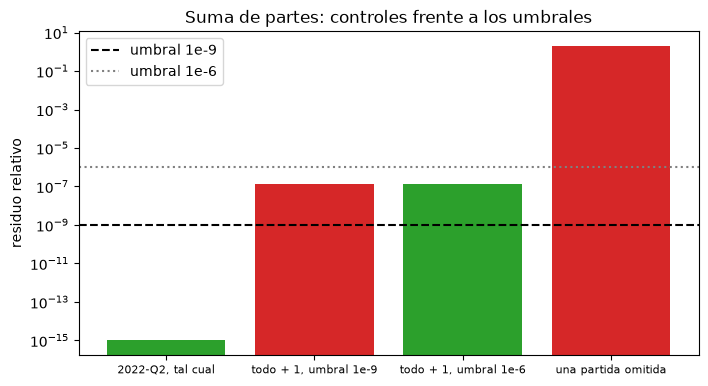

In [6]:
# Controles negativos en 2022-Q2: desplazar el todo en una unidad, aflojar el umbral y omitir una partida
item_flows, r0, whole = inputs["2022-Q2"]
cases = {
    "2022-Q2, tal cual": rv_irrbb.eve_sum_of_parts(item_flows, r0, MID, whole),
    "todo + 1, umbral 1e-9": rv_irrbb.eve_sum_of_parts(item_flows, r0, MID, whole + 1.0),
    "todo + 1, umbral 1e-6": rv_irrbb.eve_sum_of_parts(item_flows, r0, MID, whole + 1.0, rel_tol=1e-6),
    "una partida omitida": rv_irrbb.eve_sum_of_parts(item_flows[1:], r0, MID, whole),
}
for label, run in cases.items():
    print(f"{label:28s} residuo relativo {run.metric:.2e} | {LIGHT[run.light.value]}")
colours = {"green": "tab:green", "red": "tab:red"}
fig, ax = plt.subplots(figsize=(8, 4.2))
heights = [max(run.metric, 1e-18) for run in cases.values()]
ax.bar(list(cases), heights, color=[colours[run.light.value] for run in cases.values()])
ax.axhline(1e-9, color="black", linestyle="--", label="umbral 1e-9")
ax.axhline(1e-6, color="grey", linestyle=":", label="umbral 1e-6")
ax.set_yscale("log")
ax.set_ylabel("residuo relativo")
ax.set_title("Suma de partes: controles frente a los umbrales")
ax.tick_params(axis="x", labelsize=8)
ax.legend()
plt.show()

Las barras se pintan con la luz que devolvió la prueba. El balance intacto queda en el piso del gráfico, así que su barra casi no se ve; desplazar el todo en una unidad sube el residuo a 1,4 x 10^-7, sobre el umbral punteado de 10^-9, y la luz pasa a rojo; el mismo desplazamiento bajo el umbral de puntos de 10^-6 sigue verde, así que el umbral decide qué puede ver la prueba; y omitir una partida lleva el residuo a 2,03 y la luz a rojo. La prueba no puede ver un error presente en las partidas y en el todo a la vez, porque compara uno con otro. La figura muestra que la prueba está viva, no que el balance sea correcto.

### Paso 3: la estabilidad de los pesos replicantes

El notebook 03 mostró que los pesos de la cartera replicante son una estimación con un objetivo plano. `irrbb.nmd_parameter_stability` mide cuánto se mueven cuando se mueve la ventana de estimación (dossier 05, D.3; BCBS d368). El proceso del producto reestima los pesos en tres ventanas de 16 trimestres que terminan en la fecha de valoración, un año antes y dos años antes. El estadístico es la mayor distancia de norma infinito entre los pesos de ventanas consecutivas, $\max_j |w_{a,j} - w_{b,j}|$; la métrica es el mayor cambio del plazo promedio ponderado entre ventanas consecutivas, en años. La luz es verde hasta 0,10, ámbar hasta 0,25 y roja por encima. La celda siguiente la corre desde los pesos versionados de cada fecha e imprime los pesos, los plazos y las distancias.

2021-Q4: ventanas que terminan ['2019-12-31', '2020-12-31', '2021-12-31']
    peso del tramo de 10 años por ventana [0.794, 0.426, 0.951]
    plazo promedio (a) por ventana [3.995, 2.204, 4.759]
    distancias [0.367, 0.524] | estadístico 0.5243
    cambio de plazo (a) 2.5559 | rojo
2022-Q2: ventanas que terminan ['2020-06-30', '2021-06-30', '2022-06-30']
    peso del tramo de 10 años por ventana [0.544, 0.74, 0.837]
    plazo promedio (a) por ventana [2.775, 3.734, 4.205]
    distancias [0.197, 0.097] | estadístico 0.1967
    cambio de plazo (a) 0.9588 | ámbar
2022-Q4: ventanas que terminan ['2020-12-31', '2021-12-31', '2022-12-31']
    peso del tramo de 10 años por ventana [0.426, 0.951, 1.0]
    plazo promedio (a) por ventana [2.204, 4.759, 5.0]
    distancias [0.524, 0.049] | estadístico 0.5243
    cambio de plazo (a) 2.5559 | rojo


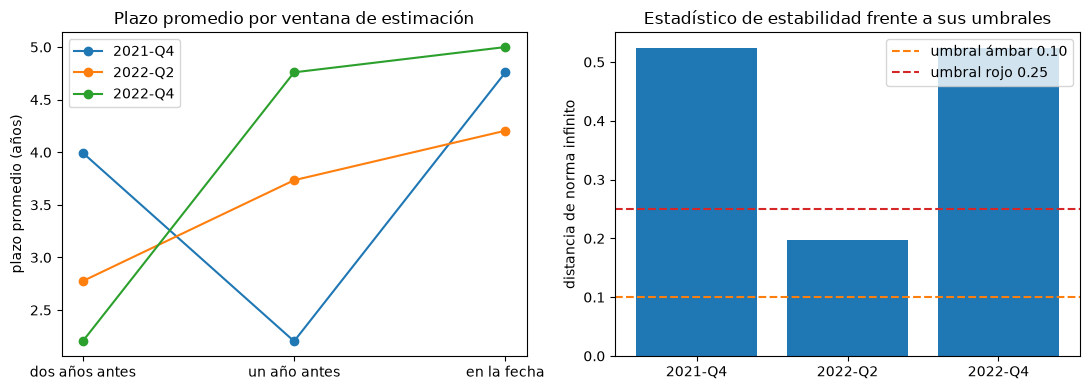

In [7]:
# Correr la prueba de estabilidad en las tres ventanas de estimación de cada fecha
windows = {}
battery["irrbb.nmd_parameter_stability"] = []
for q, d in docs.items():
    model = next(m for m in fit["nmd_models"] if m["valuation_date"] == d["outputs"]["valuation_date"])
    weights = np.array([w["weights"] for w in model["stability"]])
    maturities = np.array([t["maturity_years"] for t in model["tranches"]])
    run = rv_irrbb.nmd_parameter_stability(weights, maturities)
    windows[q] = run
    battery["irrbb.nmd_parameter_stability"].append(run.light.value)
    print(f"{q}: ventanas que terminan {[w['window_end'] for w in model['stability']]}")
    print(f"    peso del tramo de 10 años por ventana {[round(float(w[-1]), 3) for w in weights]}")
    print(f"    plazo promedio (a) por ventana {[round(x, 3) for x in run.extras['weighted_average_maturity']]}")
    print(f"    distancias {[round(x, 3) for x in run.extras['distances']]} | estadístico {run.statistic:.4f}")
    print(f"    cambio de plazo (a) {run.metric:.4f} | {LIGHT[run.light.value]}")
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
for q, run in windows.items():
    left.plot([1, 2, 3], run.extras["weighted_average_maturity"], marker="o", label=q)
left.set_xticks([1, 2, 3], ["dos años antes", "un año antes", "en la fecha"])
left.set_ylabel("plazo promedio (años)")
left.set_title("Plazo promedio por ventana de estimación")
left.legend()
right.bar(list(windows), [run.statistic for run in windows.values()], color="tab:blue")
right.axhline(0.10, color="tab:orange", linestyle="--", label="umbral ámbar 0.10")
right.axhline(0.25, color="tab:red", linestyle="--", label="umbral rojo 0.25")
right.set_ylabel("distancia de norma infinito")
right.set_title("Estadístico de estabilidad frente a sus umbrales")
right.legend()
fig.tight_layout()
plt.show()

El panel izquierdo son los mismos depósitos estimados en tres ventanas, que terminan dos años antes, un año antes y en la fecha. En 2021-Q4 el plazo promedio va 3,995, 2,204 y 4,759 años, un vaivén de 2,56 años entre ventanas consecutivas, y en 2022-Q4 va 2,204, 4,759 y 5,000; solo 2022-Q2, con 2,775, 3,734 y 4,205 años, se mueve menos de un año por vez. El panel derecho pone la distancia de norma infinito de cada fecha frente a los dos umbrales: 0,5243 en 2021-Q4 y en 2022-Q4, roja sobre 0,25, y 0,1967 en 2022-Q2, ámbar. El valor que el banco informaría es el de la última ventana, así que la ventana es una palanca: otra fecha de término mueve el plazo de los depósitos en años. Es el resultado más débil del caso y el que un validador debe poner primero; la imagen muestra que la respuesta depende de la ventana, no cuál ventana es la correcta.

### Paso 4: las dos lecturas del EVE juntas

`irrbb.eve_with_without_behavioural` se construyó en el notebook 03 con las dos medidas de riesgo EVE: es verde hasta 0,05 del Tier 1, ámbar hasta 0,15, roja por encima, y roja sea cual sea el tamaño si la medida conductual pasa la línea de 15 por ciento y la contractual la supera. Aquí la celda siguiente toma las dos medidas de los escenarios versionados (calibración 2024) en cada fecha y corre la prueba; luego corre tres pares construidos de medidas, uno cercano, uno separado y uno que esconde un exceso, para mostrar las tres luces.

2021-Q4                      estadístico 0.7222 | rojo
    exceso escondido: no
2022-Q2                      estadístico 0.5623 | rojo
    exceso escondido: no
2022-Q4                      estadístico 0.4655 | rojo
    exceso escondido: no
construido: cercanas         estadístico 0.0200 | verde
    exceso escondido: no
construido: separadas        estadístico 0.1000 | ámbar
    exceso escondido: no
construido: esconde un exceso estadístico 0.2600 | rojo
    exceso escondido: sí


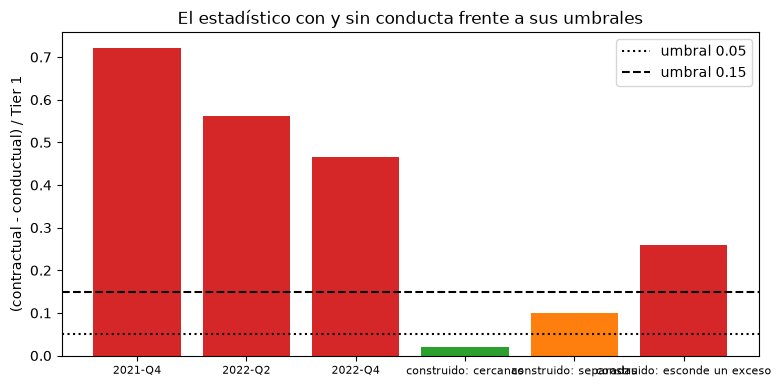

In [8]:
# Correr la prueba con y sin conducta en las tres fechas y con tres pares construidos de medidas
battery["irrbb.eve_with_without_behavioural"] = []
cases = {}
for q, d in docs.items():
    blocks = {b["nmd_assumption"]: b for b in d["outputs"]["scenarios"] if b["calibration"] == "2024"}
    beh, con = blocks["behavioural"]["eve_risk_measure"], blocks["contractual"]["eve_risk_measure"]
    cases[q] = rv_irrbb.eve_with_without_behavioural(beh, con, blocks["behavioural"]["outlier"]["tier1"])
    battery["irrbb.eve_with_without_behavioural"].append(cases[q].light.value)
pairs = {"construido: cercanas": (0.20, 0.22), "construido: separadas": (0.20, 0.30)}
pairs["construido: esconde un exceso"] = (0.14, 0.40)
for label, (beh, con) in pairs.items():
    cases[label] = rv_irrbb.eve_with_without_behavioural(beh * 1000.0, con * 1000.0, 1000.0)
for label, run in cases.items():
    print(f"{label:28s} estadístico {run.statistic:.4f} | {LIGHT[run.light.value]}")
    flag = ("no", "sí")[run.extras["hidden_breach"]]
    print(f"    exceso escondido: {flag}")
colours = {"green": "tab:green", "amber": "tab:orange", "red": "tab:red"}
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.bar(list(cases), [run.statistic for run in cases.values()], color=[colours[r.light.value] for r in cases.values()])
ax.axhline(0.05, color="black", linestyle=":", label="umbral 0.05")
ax.axhline(0.15, color="black", linestyle="--", label="umbral 0.15")
ax.set_ylabel("(contractual - conductual) / Tier 1")
ax.set_title("El estadístico con y sin conducta frente a sus umbrales")
ax.tick_params(axis="x", labelsize=8)
ax.legend()
plt.show()

Las tres primeras barras son el banco en sus tres fechas: la diferencia entre la medida contractual y la conductual es 0,7222, 0,5623 y 0,4655 del Tier 1, muy sobre el umbral rojo de 0,15, así que las luces son rojas, y la marca de exceso escondido es no porque ambas medidas superan la línea de 15 por ciento. Las tres barras construidas muestran las otras luces: una diferencia de 0,02 es verde, 0,10 es ámbar, y el par 0,14 y 0,40 es rojo con 0,26 y la marca en sí, porque la medida conductual pasa la línea y la contractual no. La imagen muestra cómo se lee la regla. No puede decir cuál de las dos lecturas es la verdad, solo que el banco las informó muy separadas, y que la brecha se angosta a lo largo de las tres fechas.

### Paso 5: el cambio ante un incumplimiento de límite

La revisión de la Reserva Federal sobre Silicon Valley Bank encontró que el banco "hizo supuestos de modelación contraintuitivos sobre la duración de los depósitos para enfrentar el incumplimiento del límite en vez de gestionar el riesgo real" (Board of Governors of the Federal Reserve System, 2023, https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf; dossier 05, D.7). `irrbb.behavioural_change_at_breach` lo convierte en una prueba: dada una serie de valores de un parámetro de comportamiento en fechas crecientes y una marca por fecha que dice si se incumplió un límite en la ventana que termina allí, cuenta las fechas en que el valor cambió ($v_t \ne v_{t-1}$) y la marca es verdadera. El estadístico es ese conteo; la luz es roja si es al menos uno, verde si es cero, `not_evaluated` con menos de dos fechas. En C14 el parámetro es el plazo promedio ponderado de la cartera replicante ajustada de los depósitos mayoristas, y la marca es la prueba de valores atípicos estandarizada de la fecha. La celda siguiente construye el historial hasta cada fecha desde los valores versionados y corre el motor, y luego lo corre con dos controles, un parámetro que nunca cambia y un parámetro que cambia sin que se incumpla ningún límite. El notebook 08 examina qué discrimina y qué no discrimina la prueba.

fechas de la historia: ['2021-12-31', '2022-06-30', '2022-12-31']
plazo promedio (a): [4.7595 4.2049 5.    ] | marca de exceso: [ True  True  True]
2021-12-31: n = 1 | no evaluado
    cambios marcados: []
2022-06-30: n = 2 | rojo
    cambios marcados: ['2022-06-30']
2022-12-31: n = 3 | rojo
    cambios marcados: ['2022-06-30', '2022-12-31']
parámetro constante: verde | cambios marcados: []
cambios sin exceso: verde | cambios marcados: []


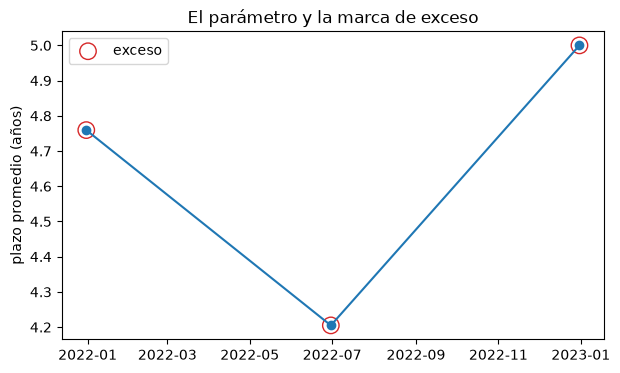

In [9]:
# Construir el historial del plazo promedio y de la marca de exceso hasta cada fecha y correr la prueba
dates = [d["outputs"]["valuation_date"] for d in docs.values()]
by_date = {m["valuation_date"]: m["weighted_average_maturity_years"] for m in fit["nmd_models"]}
values = np.array([by_date[day] for day in dates])
breach = np.array([bool(d["outputs"]["scenarios"][0]["outlier"]["breached"]) for d in docs.values()])
stamp = np.array(dates, dtype="datetime64[D]")
print("fechas de la historia:", dates)
print("plazo promedio (a):", np.round(values, 4), "| marca de exceso:", breach)
battery["irrbb.behavioural_change_at_breach"] = []
for k in (1, 2, 3):
    run = rv_irrbb.behavioural_change_at_breach(values[:k], stamp[:k], breach[:k])
    battery["irrbb.behavioural_change_at_breach"].append(run.light.value)
    print(f"{dates[k - 1]}: n = {run.n} | {LIGHT[run.light.value]}")
    print(f"    cambios marcados: {run.extras.get('flagged_dates', [])}")
ctrl = {"parámetro constante": (np.full(3, values[0]), breach)}
ctrl["cambios sin exceso"] = (values, np.zeros(3, dtype=bool))
for label, (series, flag) in ctrl.items():
    control = rv_irrbb.behavioural_change_at_breach(series, stamp, flag)
    print(f"{label}: {LIGHT[control.light.value]} | cambios marcados: {control.extras.get('flagged_dates', [])}")
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(stamp, values, marker="o", color="tab:blue")
ax.scatter(stamp[breach], values[breach], s=140, facecolors="none", edgecolors="tab:red", label="exceso")
ax.set_ylabel("plazo promedio (años)")
ax.set_title("El parámetro y la marca de exceso")
ax.legend()
plt.show()

La línea es el plazo promedio ponderado de los depósitos mayoristas ajustados en las tres fechas, 4,76, 4,20 y 5,00 años, y los círculos rojos marcan las fechas en que se incumple la prueba de valores atípicos estandarizada: las tres. La prueba necesita dos fechas para comparar, así que la primera no se evalúa; en la segunda el parámetro cambió y se incumplió un límite, un cambio marcado, rojo; en la tercera cambió otra vez, dos cambios marcados, rojo. Los controles se portan como dice la regla: un parámetro que nunca cambia, o uno que cambia sin que se incumpla ningún límite, es verde. Valen dos advertencias. Todas las fechas están en incumplimiento, y el parámetro se ajusta de nuevo en cada fecha, así que se mueve por construcción; el rojo dice que el patrón está presente, no que alguien eligió el número para aliviar un incumplimiento. El notebook 08 lo desarma.

### Paso 6: la proyección fuera de muestra

`irrbb.nii_out_of_sample` se corrió en el notebook 04 con la proyección de 2021-Q4 (un error relativo de 16,2 por ciento, ámbar). Las otras dos fechas no tienen año realizado. La celda siguiente la corre con la proyección de 2021-Q4, con una proyección a menos de 5 por ciento del cambio realizado, con una del doble y con un cambio realizado ausente, y luego dibuja toda la batería del caso, una luz por prueba y fecha.

proyección de 2021-Q4        ámbar | error relativo 0.1617
5% de la realizada           verde | error relativo 0.0500
el doble de la realizada     rojo | error relativo 1.0000
sin cambio realizado         no evaluado | error relativo nan


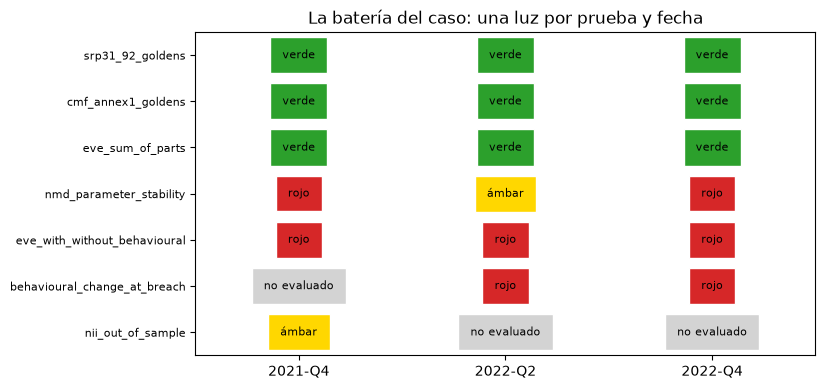

In [10]:
# La prueba fuera de muestra con la proyección de 2021-Q4 y tres controles, y luego la batería del caso
oos = docs["2021-Q4"]["outputs"]["out_of_sample"]
projected, realised = oos["projected_delta_nii"], oos["realised_delta_nii"]
controls = {"proyección de 2021-Q4": (projected, realised), "5% de la realizada": (realised * 1.05, realised)}
controls.update({"el doble de la realizada": (realised * 2.0, realised), "sin cambio realizado": (projected, None)})
for label, (proj, real) in controls.items():
    run = rv_irrbb.nii_out_of_sample(proj, real)
    print(f"{label:28s} {LIGHT[run.light.value]} | error relativo {run.statistic:.4f}")
battery["irrbb.nii_out_of_sample"] = []
for d in docs.values():
    o = d["outputs"]["out_of_sample"]
    run = rv_irrbb.nii_out_of_sample(o["projected_delta_nii"] or 0.0, o["realised_delta_nii"])
    battery["irrbb.nii_out_of_sample"].append(run.light.value)
tint = {"green": "tab:green", "amber": "gold", "red": "tab:red", "not_evaluated": "lightgrey"}
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.set_xlim(-0.5, 2.5)
ax.set_ylim(len(battery) - 0.5, -0.5)
ax.set_xticks(range(3), list(docs))
ax.set_yticks(range(len(battery)), [k.replace("irrbb.", "") for k in battery], fontsize=8)
for i, row in enumerate(battery.values()):
    for j, light in enumerate(row):
        box = {"facecolor": tint[light], "edgecolor": "white", "boxstyle": "square,pad=1.1"}
        ax.text(j, i, LIGHT[light], ha="center", va="center", fontsize=8, bbox=box)
ax.set_title("La batería del caso: una luz por prueba y fecha")
plt.show()

Primero van los controles impresos: la proyección de 2021-Q4 es ámbar con un error relativo de 0,1617, una a menos de 5 por ciento del cambio realizado es verde, una del doble es roja con un error de 1,0, y un cambio realizado ausente no devuelve ningún número. La grilla es el caso en una página. Las dos pruebas de valores de referencia y la suma de partes son verdes en todas las fechas; la prueba con y sin conducta es roja en las tres fechas, la de estabilidad es roja en 2021-Q4 y 2022-Q4 y ámbar en 2022-Q2, el cambio ante un exceso es rojo donde se puede evaluar, y la prueba fuera de muestra es ámbar en 2021-Q4 y no evaluada en las otras dos. El patrón es que las pruebas de aritmética son verdes y las de los supuestos de comportamiento no. Los umbrales son internos de Contraste, así que un rojo es un hallazgo que leer, no un incumplimiento.

## Resultados

**Respuesta:** las pruebas de aritmética pasan y las de los supuestos de comportamiento no, y toda prueba se pone roja cuando se rompe su insumo, así que los verdes significan algo. La suma de partes es verde en las tres fechas con residuos relativos de 2,07e-16, 1,06e-15 y 2,48e-15, se pone roja cuando el todo se desplaza en una unidad (un residuo de 1,42e-07 frente a un umbral de 1e-9) y cuando se omite una partida (2,03). La estabilidad de los pesos replicantes es roja en 2021-Q4 y 2022-Q4 con un estadístico de 0,5243 y ámbar en 2022-Q2 con 0,1967, y la prueba con y sin conducta es roja en las tres fechas con estadísticos de 0,7222, 0,5623 y 0,4655.

- **Los valores de referencia.** Las dos pruebas son verdes: el ejemplo resuelto del estándar tiene un estadístico de 0,0393 (el aplanamiento, a la precisión impresa) y el Anexo 1 chileno pasa 19 de 19 casos sin ninguno fallido. Con la tolerancia estrechada a 0,01 pb la primera se pone roja. Dicen que la implementación reproduce lo que las fuentes imprimen; no dicen que las fuentes se apliquen correctamente a un balance.
- **La suma de partes.** El residuo es del orden de 10^-15 en las tres fechas y en el tramo en pesos de C15 (2,35e-16 sobre 12 partidas), seis órdenes de magnitud bajo el umbral de 10^-9. Los controles muestran que la prueba está viva, y también que el umbral decide qué puede ver: el mismo desplazamiento de una unidad es verde con un umbral de 10^-6. La prueba no puede ver un error presente en las partidas y en el todo a la vez.
- **La estabilidad de los pesos.** El plazo promedio de los depósitos mayoristas depende de la ventana en que se estima: 3,995, 2,204 y 4,759 años en 2021-Q4, un vaivén de 2,5559 años entre ventanas consecutivas, y 2,204, 4,759 y 5,000 en 2022-Q4. El valor que el banco informaría es el de la última ventana, así que la ventana es una palanca. Es el resultado más débil del caso.
- **Las dos lecturas del EVE.** La prueba con y sin conducta es roja en las tres fechas sin exceso escondido: la medida conductual y la contractual están del mismo lado de la línea de 15 por ciento, pero muy separadas. Los pares construidos dan verde con 0,0200, ámbar con 0,1000 y un rojo con exceso escondido con 0,2600.
- **El cambio ante un exceso.** El plazo promedio ponderado es 4,7595, 4,2049 y 5,0 años en las tres fechas y la prueba de valores atípicos se incumple en las tres. La prueba no se evalúa en la primera fecha, es roja en la segunda (un cambio marcado, en 2022-06-30) y roja en la tercera (dos). Todas las fechas están en incumplimiento y el parámetro se reestima en cada una, así que se mueve por construcción; el rojo dice que el patrón está presente, no que alguien eligió el número. Un parámetro constante, o un cambio sin exceso, es verde. El notebook 08 lo desarma.
- **La prueba fuera de muestra.** Ámbar en 2021-Q4 (un error relativo de 0,1617), verde para una proyección a menos de 5 por ciento, roja para una del doble del cambio realizado, y no evaluada en las otras dos fechas, donde el banco no presentó reportes posteriores.
- **Lo que afirman las pruebas.** Los umbrales son umbrales internos de Contraste, no regulatorios: un rojo es un hallazgo que leer, no un incumplimiento. No muestran si un balance en verde es correcto; muestran que es internamente consistente.

## Resumen

- El motor guarda siete pruebas de validación de IRRBB; cada una es una función que devuelve un `TestResult`, declara su regla de luz y registra sus umbrales como umbrales internos de Contraste, nunca como regulación.
- Se muestra que una prueba no es vacía cambiando un insumo: un desplazamiento de una unidad del todo pone en rojo la suma de partes, un umbral más laxo la pone en verde, y una partida faltante la pone en rojo.
- La estabilidad de los pesos replicantes es el resultado más débil: roja en dos de tres fechas, con vaivenes del plazo promedio de más de dos años entre ventanas.
- La prueba que marca un cambio de comportamiento ante un exceso es roja en dos fechas, y el notebook 08 examina qué significa y qué no significa eso; la prueba fuera de muestra se evalúa en una sola fecha, porque el banco no presentó reportes posteriores.

**Qué probar a continuación.** Cambia `gap_amber` y `gap_red` en `nmd_parameter_stability` y mira qué fechas cambian de color. Después sigue con el notebook 06, el Anexo 1 chileno.

## Referencias

- BCBS, Standards: Interest rate risk in the banking book, SRP31.90 a SRP31.92 (el ejemplo resuelto), SRP31.82 a SRP31.83 y SRP31.129. https://www.bis.org/basel_framework/chapter/SRP/31.htm
- BCBS (2016), d368, Standards: Interest rate risk in the banking book (la cartera replicante y la estabilidad de sus pesos). https://www.bis.org/bcbs/publ/d368.htm
- Board of Governors of the Federal Reserve System (2023), Review of the Federal Reserve's Supervision and Regulation of Silicon Valley Bank. https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf
- CMF, Recopilación Actualizada de Normas, capítulo 21-13, Anexo 1 (las fórmulas y tablas chilenas), según se transcriben en el dossier 03, F.2, y en la prueba de referencia del motor.
- FDIC, BankFind financials, dominio público. https://api.fdic.gov/banks/financials
- Departamento del Tesoro de EE. UU., Daily Treasury Par Yield Curve Rates, dominio público. https://home.treasury.gov/resource-center/data-chart-center/interest-rates
- Dossier 05 de la investigación de Contraste, secciones D.3 y D.7.